# 04 · The Bayesian structural model

A model whose parameters mean something (DESIGN §7.3): the temperature at which heating starts,
the megawatts per degree, what a holiday does to each hour. It is fitted with NumPyro and scored on
the validation year (2024-11-01 to 2025-10-31) like every other model.

Before running this notebook:

```
python -m loadforecast.models.bayes      # one NUTS fit on the training period
make evaluate                            # backtests, including the Bayesian models
```

## The model

Demand is modelled on a grid of local days $d$ by 24 hours $h$, in GW.

**Stage 1, the structural mean.**

$$
\begin{aligned}
m_{d,h} ={}& \underbrace{P_{w(d)}(h)}_{\text{weekday profile}}
  + \underbrace{\textstyle\sum_j x_{d,j}\,E_j(h)}_{\text{holiday, bridge, Christmas, August, Holy Week}}
  + \underbrace{S(d) + S_{\text{shape}}(d, h)}_{\text{yearly cycle and its effect on the shape of the day}} \\
 &+ \underbrace{L(\tau_d) + \tau_d\,D(h)}_{\text{trend in level and in shape}}
  + \underbrace{(\rho_0 + \rho_1 \tau_d)\,R_{d,h}}_{\text{solar radiation}}
  + \underbrace{\beta_H(h)\,g(T_H - T^*_{d,h}) + \beta_C(h)\,g(T^*_{d,h} - T_C)}_{\text{heating and cooling}}
\end{aligned}
$$

- $P_w(h)$: one daily profile per weekday (Fourier, 5 harmonics), shrunk towards a common profile.
  On a holiday of intensity $x$ the profile is a blend, $(1-x)$ of the weekday's and $x$ of Sunday's.
- $E_j(h)$: an extra hourly profile for each kind of special day, scaled by its intensity $x_{d,j}$.
- $\tau_d$: years since 2021. $L$ is piecewise linear with a possible change of slope every six months.
- $T^*$: hourly temperature smoothed with an exponential kernel whose half-life is estimated.
- $g(x) = \log(1 + e^{\kappa x})/\kappa$: a smooth hinge. $T_H$ and $T_C$ are the heating and cooling
  thresholds, $\beta_H(h)$ and $\beta_C(h)$ the sensitivities in GW per °C, different for each hour.
- Likelihood: each day's 24 values are multivariate Student-t around $m_d$, with a covariance that
  mixes a whole-day component and an hour-to-hour (AR(1)) component.

**Stage 2, the day-ahead error model.** With $r = y - m$ the residuals of stage 1, the forecast issued
at 10:00 on day $d-1$ uses the residuals known by then:

$$
r_{d,h} \sim t_\nu\Big(k_1(h)\,\bar r_{d-1,\,0\text{–}9} + k_2(h)\,\bar r_{d-2} + k_3(h)\,r_{d-1,h}\,\mathbb 1[h<10]
  + \textstyle\sum_{L \in \{2,7,14,21\}} k_L(h)\,r_{d-L,h},\ \Sigma\Big)
$$

**Two departures from the design document**, both forced by the data:

1. *A direct day-ahead error model in place of an AR(1) on hourly errors.* The forecast is needed
   14 to 38 hours ahead. A one-step AR is fitted on the next hour and extrapolated; this model is
   fitted on exactly the distribution the forecast needs.
2. *Two stages in place of one joint fit.* Fitted jointly, the correction absorbed the level of
   demand (errors are so persistent from day to day that the level is barely identified), leaving
   the structural mean biased by 2.3 GW and its parameters meaningless.

The price of the second point: the two stages are inferred separately, and stage 1 treats different
days as independent. Its credible intervals are therefore **too narrow**; read them as lower bounds.

In [1]:
import json
import pickle

import arviz as az
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from loadforecast.config import DATA_DIR, PROCESSED_DIR, ROOT, load_config
from loadforecast.evaluation import scoring
from loadforecast.evaluation.backtest import prepare_table
from loadforecast.evaluation.dm_test import block_bootstrap_ci, diebold_mariano
from loadforecast.models import bayes_numpyro as bm
from loadforecast.models.bayes import load_model_config, nuts_path, training_frame, two_stage_fit
from loadforecast.models.quantiles import quantile_column

pd.set_option("display.width", 200, "display.max_columns", 30, "display.float_format", "{:,.3f}".format)
plt.rcParams.update({"figure.dpi": 90, "savefig.dpi": 130, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
FIG = ROOT / "reports" / "figures"
cfg = load_config("backtest")
model_cfg = load_model_config()
TAUS = cfg["quantiles"]
QCOLS = [quantile_column(t) for t in TAUS]
HOURS = np.arange(24)

table = pd.read_parquet(PROCESSED_DIR / "hourly.parquet")
meta = json.loads((PROCESSED_DIR / "hourly.meta.json").read_text())
with open(nuts_path(meta["hash"]), "rb") as fh:
    fit = pickle.load(fh)
S, E = fit["structure"], fit["errors"]
n_chains, n_draws = fit["chains"]["structure"]["t_heat"].shape
print(f"NUTS fit on {fit['train_start']} to {fit['train_end']} ({fit['n_days']} days): "
      f"{n_chains} chains x {n_draws} draws after {fit['config']['warmup']} warm-up, {fit['seconds'] / 60:.0f} minutes")
print(f"stage 1 has {sum(int(np.prod(v.shape[1:])) for v in S.values())} parameters, "
      f"stage 2 has {sum(int(np.prod(v.shape[1:])) for v in E.values())}")

def band(values, axis=0):
    """Posterior mean and central 90% interval."""
    return values.mean(axis=axis), np.quantile(values, 0.05, axis=axis), np.quantile(values, 0.95, axis=axis)

NUTS fit on 2021-01-01 to 2024-10-30 (1399 days): 4 chains x 500 draws after 500 warm-up, 65 minutes
stage 1 has 216 parameters, stage 2 has 45


/home/biel/SpainLoadForecast/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Did the sampler work?

- $\hat R$ compares the chains with each other; values above about 1.01 mean they disagree.
- The effective sample size (ESS) is how many independent draws the chains are worth; a few hundred
  is enough for means and 90% intervals.
- A divergence is a step where the sampler could not follow the posterior; any number above zero
  deserves a look.

In [2]:
summaries = {}
for stage in ("structure", "errors"):
    summary = az.summary(az.from_dict({"posterior": fit["chains"][stage]})).apply(pd.to_numeric, errors="coerce")
    summaries[stage] = summary
    extra = fit["extra_fields"][stage]
    depth_max = 2 ** fit["config"]["max_tree_depth"] - 1
    print(f"\n{stage}: {len(summary)} scalar parameters")
    print(f"  r_hat: max {summary['r_hat'].max():.3f}; above 1.01: {(summary['r_hat'] > 1.01).sum()}, above 1.05: {(summary['r_hat'] > 1.05).sum()}")
    print(f"  ESS bulk: min {summary['ess_bulk'].min():.0f}, median {summary['ess_bulk'].median():.0f}; "
          f"ESS tail: min {summary['ess_tail'].min():.0f}; below 200: {(summary[['ess_bulk', 'ess_tail']].min(axis=1) < 200).sum()}")
    print(f"  divergences: {int(extra['diverging'].sum())} of {extra['diverging'].size}; "
          f"leapfrog steps per draw: mean {extra['num_steps'].mean():.0f}; at the tree-depth limit: {100 * (extra['num_steps'] >= depth_max).mean():.0f}%")
    print("  worst mixing:")
    print(summary.sort_values("r_hat", ascending=False).head(6)[["mean", "sd", "ess_bulk", "ess_tail", "r_hat"]].to_string())


structure: 216 scalar parameters
  r_hat: max 1.111; above 1.01: 151, above 1.05: 46
  ESS bulk: min 26, median 175; ESS tail: min 42; below 200: 113
  divergences: 0 of 2000; leapfrog steps per draw: mean 255; at the tree-depth limit: 100%
  worst mixing:
                 mean    sd ess_bulk ess_tail r_hat
profile_z[4, 8]   0.6  0.42       28       74  1.11
profile_z[3, 8]   0.5  0.42       28       90  1.11
profile_z[1, 8]   0.5  0.41       28      142  1.11
profile_z[0, 8]   0.5  0.42       29       66  1.11
profile_z[2, 8]   0.6  0.42       29       88  1.11
profile_z[4, 9]  -0.4  0.38       26       75  1.11

errors: 45 scalar parameters
  r_hat: max 1.007; above 1.01: 0, above 1.05: 0
  ESS bulk: min 486, median 2425; ESS tail: min 562; below 200: 0
  divergences: 0 of 2000; leapfrog steps per draw: mean 55; at the tree-depth limit: 0%
  worst mixing:
                mean      sd ess_bulk ess_tail r_hat
carry[5, 4]  -0.0004  0.0042     2956     1632  1.01
carry[2, 3]    0.012  0

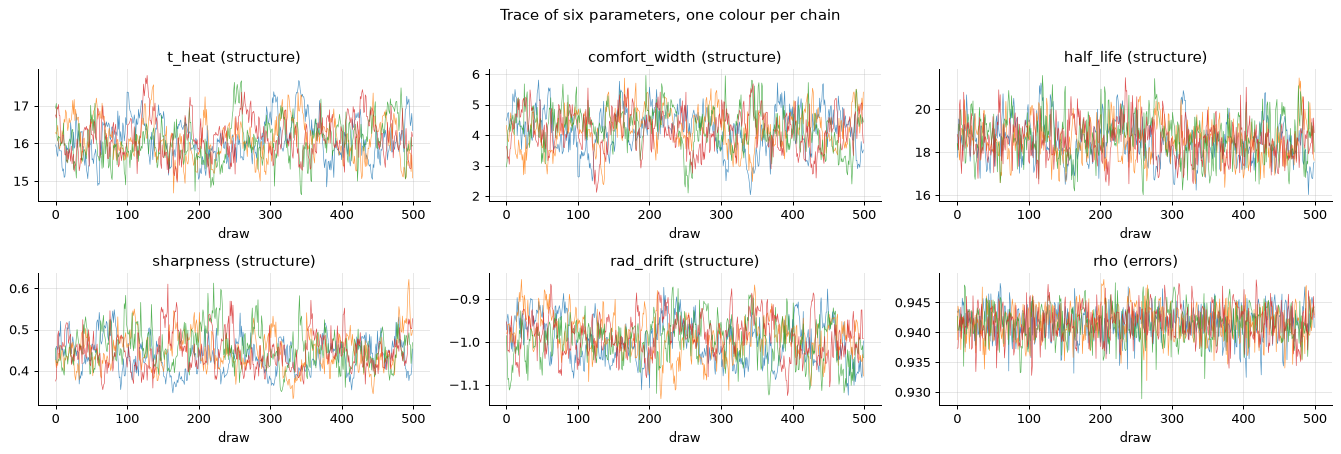

In [3]:
show = [("structure", "t_heat"), ("structure", "comfort_width"), ("structure", "half_life"),
        ("structure", "sharpness"), ("structure", "rad_drift"), ("errors", "rho")]
fig, axes = plt.subplots(2, 3, figsize=(15, 5))
for ax, (stage, name) in zip(axes.ravel(), show, strict=True):
    for chain in fit["chains"][stage][name]:
        ax.plot(chain, lw=0.5, alpha=0.8)
    ax.set(title=f"{name} ({stage})", xlabel="draw")
fig.suptitle("Trace of six parameters, one colour per chain", y=1.0)
fig.tight_layout()
fig.savefig(FIG / "bayes_traces.png", bbox_inches="tight")
plt.show()

## 2. The temperature response

The headline interpretable result: when heating and cooling start, how strong they are, and how
long the weather is "remembered".

                                               mean    sd     5%    95%
heating threshold T_H (°C)                    16.13  0.53  15.31  17.03
cooling threshold T_C (°C)                    20.32  0.21  19.97  20.66
comfort band width (°C)                        4.19  0.66   3.06   5.22
temperature half-life (hours)                 18.58  0.93  17.06  20.16
hinge sharpness (1/°C)                         0.45  0.04   0.38   0.52
heating sensitivity, mean over hours (MW/°C) 448.18 20.17 416.74 482.05
cooling sensitivity, mean over hours (MW/°C) 845.79 29.15 799.74 895.75

equivalent daily smoothing weight (EDA used 0.6): 0.41
the hinge turns over a range of about ±4.5 °C around each threshold


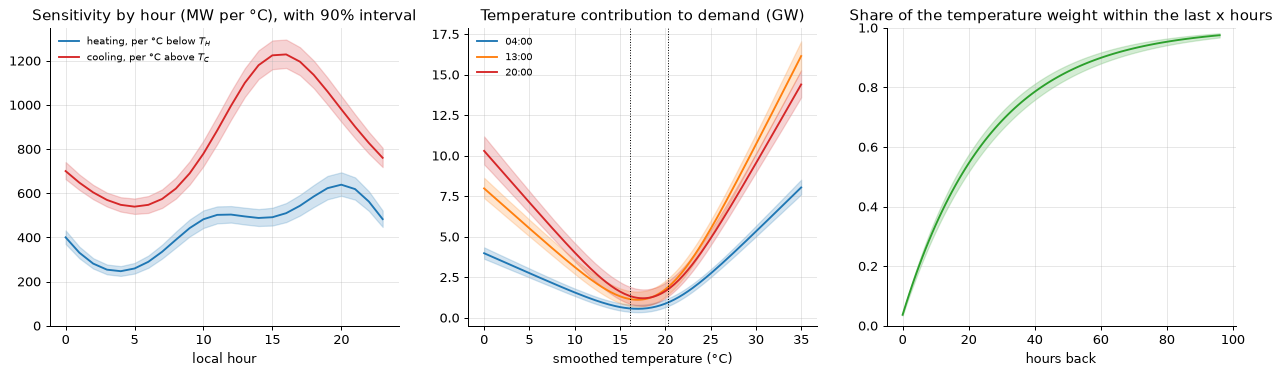

sensitivity by hour, posterior mean (MW/°C):
             0       1       2       3       4       5       6       7       8       9       10      11      12        13        14        15        16        17        18        19      20      21      22      23
heating 400.000 331.000 281.000 254.000 247.000 259.000 290.000 335.000 389.000 442.000 482.000 502.000 503.000   495.000   488.000   491.000   510.000   543.000   585.000   623.000 639.000 619.000 562.000 483.000
cooling 700.000 648.000 604.000 570.000 548.000 539.000 548.000 574.000 621.000 690.000 779.000 885.000 996.000 1,100.000 1,180.000 1,225.000 1,229.000 1,196.000 1,136.000 1,061.000 980.000 901.000 828.000 761.000


In [4]:
t_cool = S["t_heat"] + S["comfort_width"]
heat = 1000 * np.exp(S["log_heat"] @ bm.H_EXTRA.T)        # (draws, 24) MW per °C
cool = 1000 * np.exp(S["log_cool"] @ bm.H_EXTRA.T)
scalars = pd.DataFrame({
    "heating threshold T_H (°C)": S["t_heat"],
    "cooling threshold T_C (°C)": t_cool,
    "comfort band width (°C)": S["comfort_width"],
    "temperature half-life (hours)": S["half_life"],
    "hinge sharpness (1/°C)": S["sharpness"],
    "heating sensitivity, mean over hours (MW/°C)": heat.mean(axis=1),
    "cooling sensitivity, mean over hours (MW/°C)": cool.mean(axis=1),
})
print(pd.DataFrame({"mean": scalars.mean(), "sd": scalars.std(), "5%": scalars.quantile(0.05),
                    "95%": scalars.quantile(0.95)}).to_string(float_format=lambda v: f"{v:,.2f}"))
print(f"\nequivalent daily smoothing weight (EDA used 0.6): {np.mean(0.5 ** (24 / S['half_life'])):.2f}")
print(f"the hinge turns over a range of about ±{np.mean(2 / S['sharpness']):.1f} °C around each threshold")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
for values, color, label in [(heat, "C0", "heating, per °C below $T_H$"), (cool, "C3", "cooling, per °C above $T_C$")]:
    mean, low, high = band(values)
    axes[0].plot(HOURS, mean, color=color, label=label)
    axes[0].fill_between(HOURS, low, high, color=color, alpha=0.2)
axes[0].set(title="Sensitivity by hour (MW per °C), with 90% interval", xlabel="local hour", ylim=0)
axes[0].legend(frameon=False, fontsize=8)
temps = np.linspace(0, 35, 141)
for hour, color in [(4, "C0"), (13, "C1"), (20, "C3")]:
    k = S["sharpness"][:, None]
    resp = (heat[:, [hour]] * np.log1p(np.exp(k * (S["t_heat"][:, None] - temps))) / k
            + cool[:, [hour]] * np.log1p(np.exp(k * (temps - t_cool[:, None]))) / k) / 1000
    mean, low, high = band(resp)
    axes[1].plot(temps, mean, color=color, label=f"{hour:02d}:00")
    axes[1].fill_between(temps, low, high, color=color, alpha=0.2)
for x in (S["t_heat"].mean(), t_cool.mean()):
    axes[1].axvline(x, color="k", ls=":", lw=0.8)
axes[1].set(title="Temperature contribution to demand (GW)", xlabel="smoothed temperature (°C)")
axes[1].legend(frameon=False, fontsize=8)
lags = np.arange(0, 97)
kernel = 0.5 ** (lags[None, :] / S["half_life"][:, None])
mean, low, high = band(1 - np.cumsum(kernel, axis=1) / (0.5 ** (np.arange(bm.N_LAGS)[None, :] / S["half_life"][:, None])).sum(axis=1, keepdims=True))
axes[2].plot(lags, 1 - mean, color="C2")
axes[2].fill_between(lags, 1 - high, 1 - low, color="C2", alpha=0.2)
axes[2].set(title="Share of the temperature weight within the last x hours", xlabel="hours back", ylim=(0, 1))
fig.savefig(FIG / "bayes_temperature.png", bbox_inches="tight")
plt.show()
print("sensitivity by hour, posterior mean (MW/°C):")
print(pd.DataFrame({"heating": heat.mean(axis=0), "cooling": cool.mean(axis=0)}).T.round(0).to_string())

### Priors against posteriors

If a posterior sits on top of its prior, the data said nothing about that parameter.

t_heat: prior sd 2.00, posterior sd 0.525  (shrinkage 4x)
comfort_width: prior sd 2.26, posterior sd 0.656  (shrinkage 3x)
half_life: prior sd 24.38, posterior sd 0.925  (shrinkage 26x)
sharpness: prior sd 0.60, posterior sd 0.044  (shrinkage 14x)


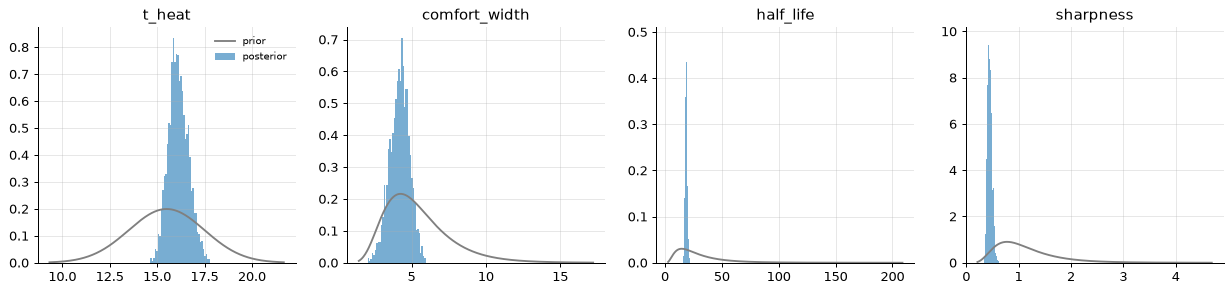

In [5]:
from scipy import stats

priors = {"t_heat": stats.norm(15.5, 2.0), "comfort_width": stats.lognorm(0.4, scale=5.0),
          "half_life": stats.lognorm(0.7, scale=24.0), "sharpness": stats.lognorm(0.5, scale=1.0)}
fig, axes = plt.subplots(1, 4, figsize=(17, 3.4))
for ax, (name, prior) in zip(axes, priors.items(), strict=True):
    x = np.linspace(prior.ppf(0.001), prior.ppf(0.999), 400)
    ax.plot(x, prior.pdf(x), color="0.5", label="prior")
    ax.hist(S[name], bins=40, density=True, color="C0", alpha=0.6, label="posterior")
    ax.set(title=name)
    print(f"{name}: prior sd {prior.std():.2f}, posterior sd {S[name].std():.3f}  (shrinkage {prior.std() / S[name].std():.0f}x)")
axes[0].legend(frameon=False, fontsize=8)
fig.savefig(FIG / "bayes_prior_posterior.png", bbox_inches="tight")
plt.show()

## 3. Calendar effects

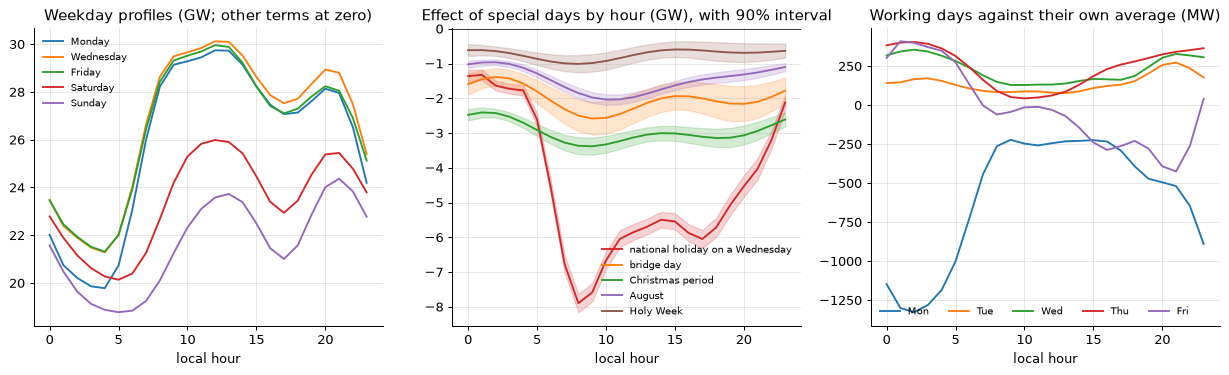

                                 daily mean (GW)    5%   95%  largest at hour  there (GW)
national holiday on a Wednesday            -4.55 -4.74 -4.35             8.00       -7.90
bridge day                                 -2.01 -2.33 -1.66             9.00       -2.58
Christmas period                           -2.97 -3.14 -2.79             9.00       -3.38
August                                     -1.47 -1.58 -1.36            10.00       -2.04
Holy Week                                  -0.74 -0.92 -0.56             8.00       -1.01

mean level of each weekday profile (GW): {'Mon': np.float64(25.9), 'Tue': np.float64(26.63), 'Wed': np.float64(26.72), 'Thu': np.float64(26.73), 'Fri': np.float64(26.47), 'Sat': np.float64(23.42), 'Sun': np.float64(21.6)}


In [6]:
profiles = (S["profile_mean"][:, None, :] + S["profile_sd"][:, None, :] * S["profile_z"]) @ bm.H_DAY.T  # (draws, 7, 24)
extra = S["extra"] @ bm.H_EXTRA.T                                                                       # (draws, 5, 24)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
for wd, name in [(0, "Monday"), (2, "Wednesday"), (4, "Friday"), (5, "Saturday"), (6, "Sunday")]:
    axes[0].plot(HOURS, profiles[:, wd].mean(axis=0) + bm.Y_CENTRE, label=name)
axes[0].set(title="Weekday profiles (GW; other terms at zero)", xlabel="local hour")
axes[0].legend(frameon=False, fontsize=8)
effects = {
    "national holiday on a Wednesday": profiles[:, 6] - profiles[:, 2] + extra[:, 0],
    "bridge day": extra[:, 1],
    "Christmas period": extra[:, 2],
    "August": extra[:, 3],
    "Holy Week": extra[:, 4],
}
for (name, values), color in zip(effects.items(), ["C3", "C1", "C2", "C4", "C5"], strict=True):
    mean, low, high = band(values)
    axes[1].plot(HOURS, mean, color=color, label=name)
    axes[1].fill_between(HOURS, low, high, color=color, alpha=0.2)
axes[1].axhline(0, color="k", lw=0.6)
axes[1].set(title="Effect of special days by hour (GW), with 90% interval", xlabel="local hour")
axes[1].legend(frameon=False, fontsize=8)
diff = profiles[:, :5] - profiles[:, :5].mean(axis=1, keepdims=True)
for wd, name in enumerate(["Mon", "Tue", "Wed", "Thu", "Fri"]):
    axes[2].plot(HOURS, 1000 * diff[:, wd].mean(axis=0), label=name)
axes[2].set(title="Working days against their own average (MW)", xlabel="local hour")
axes[2].legend(frameon=False, fontsize=8, ncol=5)
fig.savefig(FIG / "bayes_calendar.png", bbox_inches="tight")
plt.show()
rows = {name: {"daily mean (GW)": values.mean(axis=1).mean(), "5%": np.quantile(values.mean(axis=1), 0.05),
               "95%": np.quantile(values.mean(axis=1), 0.95),
               "largest at hour": int(np.abs(values.mean(axis=0)).argmax()), "there (GW)": values.mean(axis=0)[np.abs(values.mean(axis=0)).argmax()]}
        for name, values in effects.items()}
print(pd.DataFrame(rows).T.to_string(float_format=lambda v: f"{v:,.2f}"))
level = profiles.mean(axis=2).mean(axis=0) + bm.Y_CENTRE
print("\nmean level of each weekday profile (GW):", dict(zip(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], level.round(2), strict=True)))

## 4. What changes over the years

Three terms move with time: the level, the shape of the day, and the effect of solar radiation.
The last two are how the model sees the growth of rooftop solar.

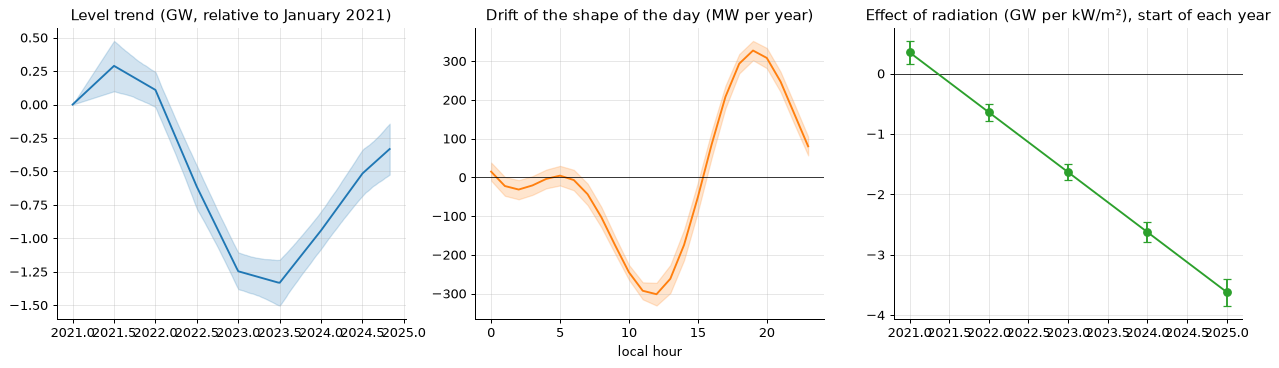

shape drift by hour (MW per year): {0: np.float64(15.0), 2: np.float64(-31.0), 4: np.float64(-4.0), 6: np.float64(-7.0), 8: np.float64(-103.0), 10: np.float64(-245.0), 12: np.float64(-302.0), 14: np.float64(-174.0), 16: np.float64(85.0), 18: np.float64(293.0), 20: np.float64(308.0), 22: np.float64(164.0)}
radiation effect (GW per kW/m²) at the start of each year: {2021: '0.35 [0.15, 0.54]', 2022: '-0.64 [-0.79, -0.50]', 2023: '-1.63 [-1.76, -1.50]', 2024: '-2.63 [-2.79, -2.46]', 2025: '-3.62 [-3.84, -3.40]'}
on a clear midday at 0.8 kW/m², the radiation term alone is worth 280 MW at the start of 2021 and -2,894 MW at the start of 2025
level change over the training period: -0.33 GW


In [7]:
tau = np.linspace(0, fit["n_days"] / 365.25, 200)
level = S["slope"][:, None] * tau + (np.maximum(tau[None, :, None] - bm.KNOTS[None, None, :], 0) * S["slope_change"][:, None, :]).sum(axis=2)
shape = S["shape_drift"] @ bm.H_SHAPE.T                    # GW per year, by hour
rad_by_year = S["rad"][:, None] + S["rad_drift"][:, None] * np.arange(0, 5)[None, :]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
mean, low, high = band(level)
axes[0].plot(2021 + tau, mean, color="C0")
axes[0].fill_between(2021 + tau, low, high, color="C0", alpha=0.2)
axes[0].set(title="Level trend (GW, relative to January 2021)")
mean, low, high = band(1000 * shape)
axes[1].plot(HOURS, mean, color="C1")
axes[1].fill_between(HOURS, low, high, color="C1", alpha=0.2)
axes[1].axhline(0, color="k", lw=0.6)
axes[1].set(title="Drift of the shape of the day (MW per year)", xlabel="local hour")
mean, low, high = band(rad_by_year)
axes[2].errorbar(2021 + np.arange(5), mean, yerr=[mean - low, high - mean], fmt="o-", color="C2", capsize=3)
axes[2].axhline(0, color="k", lw=0.6)
axes[2].set(title="Effect of radiation (GW per kW/m²), start of each year")
fig.savefig(FIG / "bayes_trends.png", bbox_inches="tight")
plt.show()
print("shape drift by hour (MW per year):", dict(zip(HOURS[::2].tolist(), (1000 * shape.mean(axis=0))[::2].round(0), strict=True)))
print("radiation effect (GW per kW/m²) at the start of each year:",
      {int(2021 + i): f"{m:.2f} [{lo:.2f}, {hi:.2f}]" for i, (m, lo, hi) in enumerate(zip(mean, low, high, strict=True))})
print(f"on a clear midday at 0.8 kW/m², the radiation term alone is worth {0.8 * mean[0] * 1000:,.0f} MW at the start of 2021 "
      f"and {0.8 * mean[4] * 1000:,.0f} MW at the start of 2025")
print(f"level change over the training period: {level.mean(axis=0)[-1]:+.2f} GW")

## 5. The day-ahead error model

What the forecast carries over from the errors it has already seen, and how much uncertainty is left.

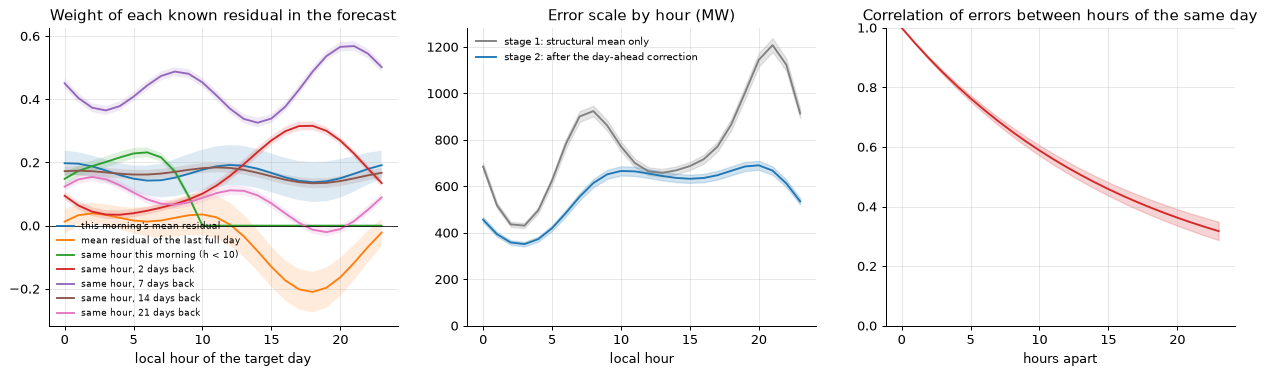

sum of the weights by hour (1 would mean the level simply follows recent errors):
{0: np.float64(1.2), 3: np.float64(1.13), 6: np.float64(1.12), 9: np.float64(1.1), 12: np.float64(1.02), 15: np.float64(0.87), 18: np.float64(0.85), 21: np.float64(1.01)}
                                    stage 1  stage 2
degrees of freedom                    26.11     7.92
whole-day share of the correlation     0.02     0.09
hour-to-hour correlation rho           0.90     0.94
mean error scale (MW)                773.20   570.81


In [8]:
carry = E["carry"] @ bm.H_EXTRA.T                       # (draws, 7, 24)
names = ["this morning's mean residual", "mean residual of the last full day", "same hour this morning (h < 10)",
         *[f"same hour, {lag} days back" for lag in bm.SAME_HOUR_LAGS]]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
for i, name in enumerate(names):
    values = carry[:, i] * (HOURS < bm.ISSUE_HOUR) if i == 2 else carry[:, i]
    mean, low, high = band(values)
    axes[0].plot(HOURS, mean, label=name)
    axes[0].fill_between(HOURS, low, high, alpha=0.15)
axes[0].axhline(0, color="k", lw=0.6)
axes[0].set(title="Weight of each known residual in the forecast", xlabel="local hour of the target day")
axes[0].legend(frameon=False, fontsize=7)
for draws, color, label in [(S, "0.5", "stage 1: structural mean only"), (E, "C0", "stage 2: after the day-ahead correction")]:
    mean, low, high = band(1000 * np.exp(draws["log_scale"] @ bm.H_SCALE.T))
    axes[1].plot(HOURS, mean, color=color, label=label)
    axes[1].fill_between(HOURS, low, high, color=color, alpha=0.2)
axes[1].set(title="Error scale by hour (MW)", xlabel="local hour", ylim=0)
axes[1].legend(frameon=False, fontsize=8)
lag = np.arange(24)
corr = E["common"][:, None] + (1 - E["common"][:, None]) * E["rho"][:, None] ** lag[None, :]
mean, low, high = band(corr)
axes[2].plot(lag, mean, color="C3")
axes[2].fill_between(lag, low, high, color="C3", alpha=0.2)
axes[2].set(title="Correlation of errors between hours of the same day", xlabel="hours apart", ylim=(0, 1))
fig.savefig(FIG / "bayes_error_model.png", bbox_inches="tight")
plt.show()
total = sum(carry[:, i] * (HOURS < bm.ISSUE_HOUR) if i == 2 else carry[:, i] for i in range(len(names)))
print("sum of the weights by hour (1 would mean the level simply follows recent errors):")
print(dict(zip(HOURS[::3].tolist(), total.mean(axis=0)[::3].round(2), strict=True)))
tab = pd.DataFrame({stage: {"degrees of freedom": 2 + d["dof"].mean(), "whole-day share of the correlation": d["common"].mean(),
                            "hour-to-hour correlation rho": d["rho"].mean(),
                            "mean error scale (MW)": 1000 * np.exp(d["log_scale"] @ bm.H_SCALE.T).mean()}
                    for stage, d in (("stage 1", S), ("stage 2", E))})
print(tab.to_string(float_format=lambda v: f"{v:,.2f}"))

## 6. Scores on the validation year

Four Bayesian variants, by how the posterior is obtained and what weather the model is fed:

| Name | Posterior | Weather at prediction time |
|---|---|---|
| `bayes_nuts_oracle`, `bayes_nuts_forecast` | the single NUTS fit above, kept fixed all year | observed / forecast |
| `bayes_svi_oracle`, `bayes_svi_forecast` | refitted every 28 days: posterior mode plus a low-rank Gaussian approximation | observed / forecast |

Their quantiles are the posterior predictive ones recalibrated on the model's own past errors (`recalibrate_quantiles`); the quantiles as sampled are kept in the `model_q*` columns.

In [9]:
results = pd.read_csv(ROOT / "reports" / "results" / "validation.csv", index_col=0)
print(results[["MAE", "RMSE", "MAPE", "bias", "CRPS", "cov50", "cov80", "cov90", "width90", "skill_MAE", "skill_CRPS"]]
      .to_string(float_format=lambda v: f"{v:,.2f}"))
BAYES = [m for m in results.index if m.startswith("bayes")]
MODELS = [*BAYES, "lgbm_forecast", "ree"]
scored = {m: scoring.join_actual(pd.read_parquet(DATA_DIR / "predictions" / "validation" / f"{m}.parquet"), table)
          for m in MODELS}
daily = {m: scoring.daily_losses(scored[m], TAUS) for m in MODELS}
def compare(a, b):
    both = daily[a].add_suffix("_a").join(daily[b].add_suffix("_b")).dropna()
    out = {}
    for loss, label in (("abs_error", "daily MAE"), ("crps", "daily CRPS")):
        test = diebold_mariano(both[f"{loss}_a"], both[f"{loss}_b"])
        low, high = block_bootstrap_ci(both[f"{loss}_a"], both[f"{loss}_b"])
        out[label] = f"{test['mean_diff']:+.0f} MW  [{low:+.0f}, {high:+.0f}]  p = {test['p_value']:.2g}"
    return out
pairs = [("bayes_nuts_forecast", "ree"), ("bayes_nuts_forecast", "lgbm_forecast"), ("bayes_nuts_forecast", "bayes_nuts_oracle"),
         ("bayes_svi_forecast", "bayes_nuts_forecast")]
print()
print(pd.DataFrame({f"{a} minus {b}": compare(a, b) for a, b in pairs}).T.to_string())
s = scored["bayes_nuts_forecast"]
structural = 100 * ((s["structural_mean"] - s["y"]).abs() / s["y"]).mean()
print(f"\nstructural mean alone (no day-ahead correction): MAPE {structural:.2f}%; with the correction: {results.loc['bayes_nuts_forecast', 'MAPE']:.2f}%")

                          MAE     RMSE  MAPE    bias     CRPS  cov50  cov80  cov90  width90  skill_MAE  skill_CRPS
model                                                                                                             
naive_daily          2,442.86 3,358.29  9.08   -2.44 1,390.05  50.33  80.35  89.46 9,940.23      -0.70       -0.54
naive_weekly         1,438.06 2,092.41  5.30   -0.09   903.01  45.37  74.58  85.11 5,448.96       0.00        0.00
climatology_adjusted 1,233.93 1,637.16  4.53  -14.10   695.73  45.78  73.28  84.21 4,276.01       0.14        0.23
climatology          1,221.00 1,617.71  4.47 -153.30   695.70  47.60  74.41  85.04 4,363.36       0.15        0.23
bayes_nuts_forecast    585.96   813.88  2.15 -116.19   356.27  48.44  78.20  88.03 2,392.58       0.59        0.61
bayes_svi_forecast     585.53   814.12  2.15 -111.29   354.92  49.22  79.20  88.91 2,449.11       0.59        0.61
bayes_svi_oracle       582.11   803.84  2.14  -10.01   353.23  48.76  79.59  89.

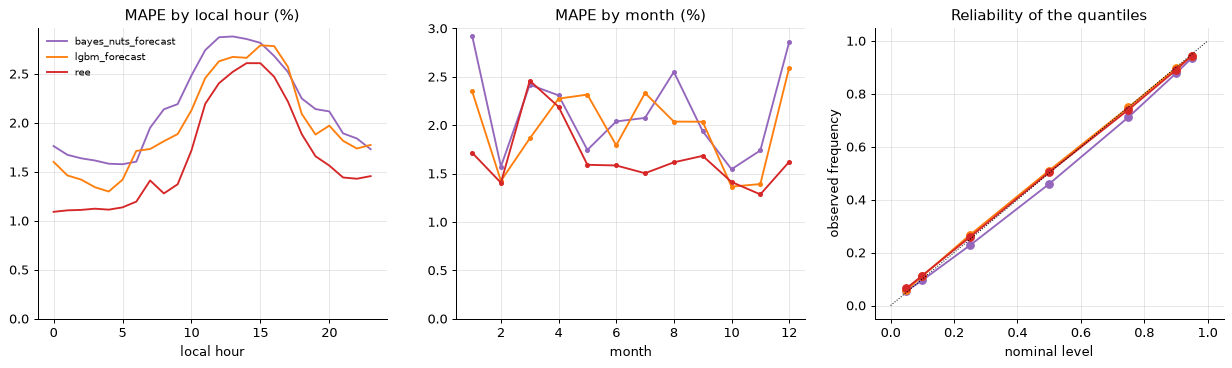

MAPE (%) by kind of day and by temperature:
                      bayes_nuts_forecast  lgbm_forecast  ree
Christmas period                     4.90           3.42 1.85
Holy Week                            3.04           2.19 1.11
Saturday                             2.21           1.93 1.65
Sunday                               1.82           2.04 1.74
bridge day                           4.71           4.46 3.17
holiday                              3.06           3.13 2.39
ordinary working day                 1.99           1.85 1.63
cold (<10 °C)                        2.18           1.95 1.41
hot (>22 °C)                         2.23           2.17 1.68
mild                                 2.09           1.89 1.75

coverage of the 90% interval by quarter (%):
local_date           2024Q4  2025Q1  2025Q2  2025Q3  2025Q4
bayes_nuts_forecast    85.2    83.6    91.1    88.3    97.0
lgbm_forecast          87.2    89.2    88.3    85.4    98.3
ree                    90.3    83.2    88.6    8

In [10]:
MAIN = ["bayes_nuts_forecast", "lgbm_forecast", "ree"]
COLORS = {"bayes_nuts_forecast": "C4", "lgbm_forecast": "C1", "ree": "C3"}
info_cols = ["day_type", "holiday_intensity", "bridge_intensity", "christmas", "holy_week", "temp_obs"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
rows = {}
for m in MAIN:
    s = scored[m].join(table[info_cols])
    ape = 100 * (s["point"] - s["y"]).abs() / s["y"]
    axes[0].plot(ape.groupby(s["local_hour"]).mean(), color=COLORS[m], label=m)
    axes[1].plot(ape.groupby(s["local_date"].dt.month).mean(), color=COLORS[m], marker=".")
    kind = np.select([s["holiday_intensity"] >= 0.3, s["bridge_intensity"] >= 0.5, s["christmas"], s["holy_week"],
                      s["day_type"] == "saturday", s["day_type"] == "sunday_holiday"],
                     ["holiday", "bridge day", "Christmas period", "Holy Week", "Saturday", "Sunday"], "ordinary working day")
    regime = pd.cut(s["temp_obs"], [-20, 10, 22, 50], labels=["cold (<10 °C)", "mild", "hot (>22 °C)"]).astype(str)
    rows[m] = pd.concat([ape.groupby(kind).mean(), ape.groupby(regime).mean()])
    q = s.dropna(subset=QCOLS)
    axes[2].plot(TAUS, [(q["y"] <= q[c]).mean() for c in QCOLS], marker="o", color=COLORS[m])
axes[0].set(title="MAPE by local hour (%)", xlabel="local hour", ylim=0)
axes[1].set(title="MAPE by month (%)", xlabel="month", ylim=0)
axes[2].plot([0, 1], [0, 1], color="k", lw=0.8, ls=":")
axes[2].set(title="Reliability of the quantiles", xlabel="nominal level", ylabel="observed frequency")
axes[0].legend(frameon=False, fontsize=8)
fig.savefig(FIG / "bayes_validation.png", bbox_inches="tight")
plt.show()
print("MAPE (%) by kind of day and by temperature:")
print(pd.DataFrame(rows).to_string(float_format=lambda v: f"{v:,.2f}"))
cov = {}
for m in MAIN:
    q = scored[m].dropna(subset=QCOLS)
    inside = (q["y"] >= q["q0.05"]) & (q["y"] <= q["q0.95"])
    cov[m] = 100 * inside.groupby(q["local_date"].dt.to_period("Q").astype(str)).mean()
print("\ncoverage of the 90% interval by quarter (%):")
print(pd.DataFrame(cov).T.to_string(float_format=lambda v: f"{v:,.1f}"))

### Example weeks

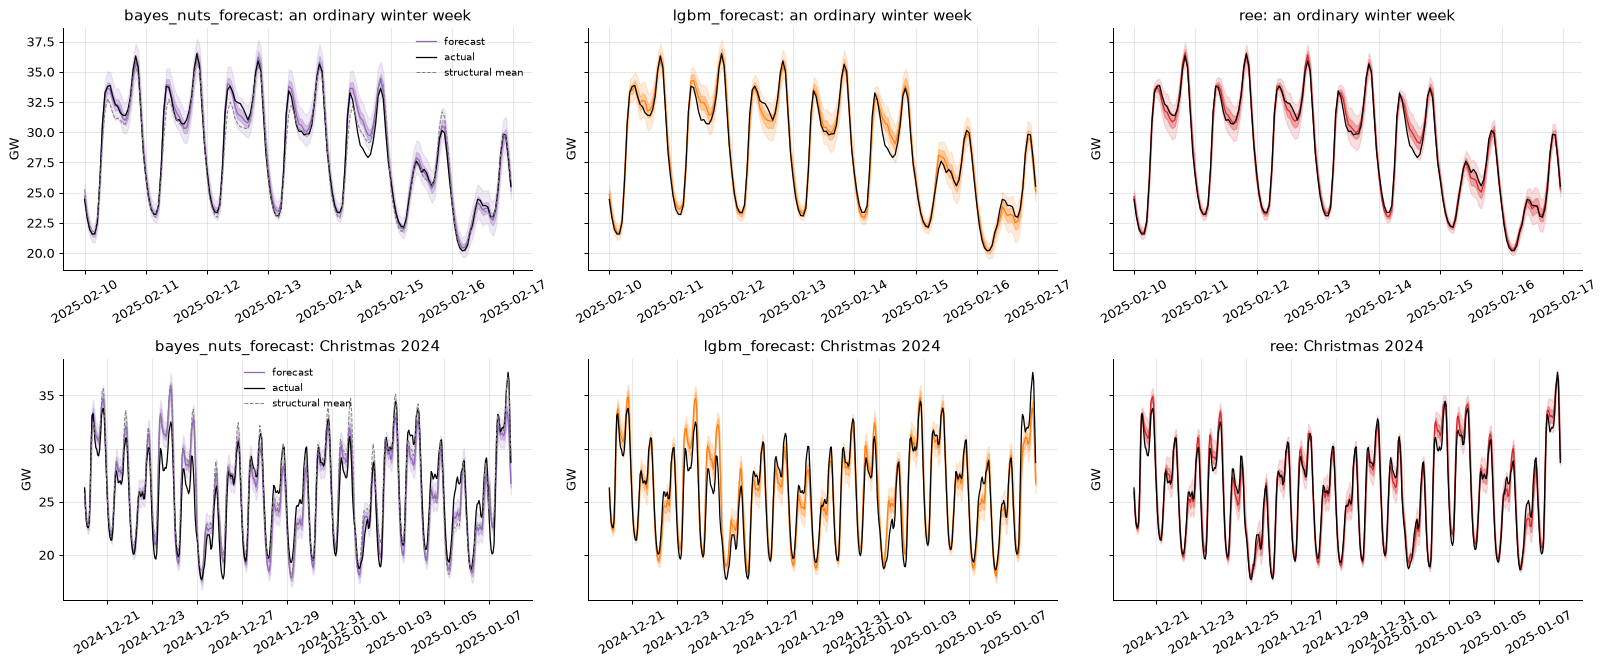

In [11]:
def plot_days(start, end, title, ax_row):
    for ax, m in zip(ax_row, MAIN, strict=True):
        s = scored[m]
        s = s[(s["local_date"] >= start) & (s["local_date"] <= end)]
        x = s.index.tz_convert("Europe/Madrid").tz_localize(None)
        ax.fill_between(x, s["q0.05"] / 1000, s["q0.95"] / 1000, color=COLORS[m], alpha=0.15)
        ax.fill_between(x, s["q0.25"] / 1000, s["q0.75"] / 1000, color=COLORS[m], alpha=0.3)
        ax.plot(x, s["point"] / 1000, color=COLORS[m], lw=1, label="forecast")
        ax.plot(x, s["y"] / 1000, color="k", lw=1, label="actual")
        if "structural_mean" in s:
            ax.plot(x, s["structural_mean"] / 1000, color="0.5", lw=0.8, ls="--", label="structural mean")
        ax.set(title=f"{m}: {title}", ylabel="GW")
        ax.tick_params(axis="x", labelrotation=30)
    ax_row[0].legend(frameon=False, fontsize=8)

fig, axes = plt.subplots(2, 3, figsize=(18, 7.5), sharey="row")
plot_days("2025-02-10", "2025-02-16", "an ordinary winter week", axes[0])
plot_days("2024-12-20", "2025-01-07", "Christmas 2024", axes[1])
fig.tight_layout()
fig.savefig(FIG / "bayes_examples.png", bbox_inches="tight")
plt.show()

## 7. Is the cheap approximation good enough?

The backtest's `svi` variants replace NUTS by the posterior mode plus a low-rank Gaussian
approximation, which takes about a minute. Here it is fitted on the same training days as the NUTS
run, to compare the two posteriors directly.

In [12]:
grid = bm.build_grid(training_frame(prepare_table(table), fit["train_start"], pd.Timestamp(fit["train_end"])))
svi = two_stage_fit(grid, model_cfg, "svi")
rows = {}
for stage, name in [("structure", "t_heat"), ("structure", "comfort_width"), ("structure", "half_life"), ("structure", "sharpness"),
                    ("structure", "rad"), ("structure", "rad_drift"), ("structure", "slope"), ("errors", "rho"), ("errors", "common"), ("errors", "dof")]:
    a, b = fit[stage][name], svi[stage][name]
    rows[f"{name} ({stage})"] = {"NUTS mean": a.mean(), "SVI mean": b.mean(), "NUTS sd": a.std(), "SVI sd": b.std(), "sd ratio SVI / NUTS": b.std() / a.std()}
print(f"SVI fit: {svi['seconds']:.0f} s against {fit['seconds'] / 60:.0f} min for NUTS")
print(pd.DataFrame(rows).T.to_string(float_format=lambda v: f"{v:,.3f}"))
ratios = []
for stage in ("structure", "errors"):
    for name in fit[stage]:
        ratios.append((svi[stage][name].std(axis=0) / fit[stage][name].std(axis=0)).ravel())
ratios = np.concatenate(ratios)
print(f"\nover all {len(ratios)} scalar parameters, SVI sd / NUTS sd: median {np.median(ratios):.2f}, "
      f"10th to 90th percentile {np.quantile(ratios, 0.1):.2f} to {np.quantile(ratios, 0.9):.2f}")

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


SVI fit: 123 s against 65 min for NUTS
                           NUTS mean  SVI mean  NUTS sd  SVI sd  sd ratio SVI / NUTS
t_heat (structure)            16.126    15.803    0.525   0.017                0.032
comfort_width (structure)      4.194     4.610    0.656   0.032                0.049
half_life (structure)         18.576    18.124    0.925   0.401                0.433
sharpness (structure)          0.447     0.453    0.044   0.005                0.114
rad (structure)                0.351     0.377    0.116   0.016                0.141
rad_drift (structure)         -0.992    -1.006    0.048   0.009                0.183
slope (structure)              0.578    -0.006    0.230   0.006                0.027
rho (errors)                   0.942     0.941    0.003   0.001                0.435
common (errors)                0.088     0.092    0.038   0.017                0.439
dof (errors)                   5.918     5.850    0.357   0.341                0.956

over all 261 scalar param

## 8. Conclusions

**Headline.** With realistic weather inputs, the Bayesian model scores MAPE 2.15%, MAE 586 MW and
CRPS 356 MW on the validation year. That is 52% less error than the best baseline (MAE 1,221 MW),
but behind LightGBM (1.99%, 538 MW, 315 MW) and REE (1.67%, 455 MW, 271 MW). In daily MAE it is
131 MW worse than REE (95% interval 76 to 184 MW, p = 1e-6) and 48 MW worse than LightGBM (4 to
92 MW, p = 0.03). It beats REE on 36% of days and LightGBM on 46%.

**It does not win on accuracy; what it adds is the reading of the parameters.**

- Heating starts below 16.1 °C (90% interval 15.3 to 17.0) and cooling above 20.3 °C (20.0 to
  20.7), close to the rough EDA fits (16 and 20 °C).
- Cooling is almost twice as strong as heating: 846 MW per °C against 448 MW per °C on average
  over the day. Cooling peaks at 16:00 (1,230 MW per °C), heating at 20:00 (640 MW per °C).
- Demand responds to temperature with a half-life of 19 hours (17 to 20).
- A national holiday on a Wednesday removes 4.6 GW on average and 7.9 GW at 08:00. A bridge day
  removes 2.0 GW, the Christmas period 3.0 GW, August 1.5 GW and Holy Week 0.7 GW.
- Rooftop solar shows up twice. The radiation effect grows by 1.0 GW per kW/m² every year, so a
  clear midday is worth about −2.9 GW at the start of 2025 and almost nothing in 2021. On top of
  that the shape of the day drifts by −300 MW per year at 12:00 and +300 MW per year at 18:00–20:00.

**The day-ahead correction matters.** The structural mean alone scores 2.72%; conditioning on the
residuals known at 10:00 brings it to 2.15%. The weights on recent residuals sum to about 1.1–1.2 at
night and 0.85 in the afternoon, so the level mostly follows recent errors.

**Where it trails**

- Every block of the day is worse than REE, most at night and in the morning (00:00–05:59: 1.64%
  against 1.11%; 06:00–10:59: 2.07% against 1.40%). The pattern is the same as LightGBM's, slightly worse.
- Special periods are its weakest point, not its strength: Christmas 4.90% (LightGBM 3.42%, REE
  1.85%), Holy Week 3.04% (2.19%, 1.11%). Pooled holiday profiles did not close the gap that
  `03_lightgbm.ipynb` hoped a structural model would close.
- It is level with LightGBM on single holidays (3.06% against 3.13%) and better on Sundays (1.82%
  against 2.04%; REE 1.74%).
- In the sunny spell of 25 March – 1 April 2025 it scores 3.70%: better than REE (4.64%), worse
  than LightGBM (2.75%).

**The uncertainty bands need recalibrating, and then they are fine.** As sampled, the 50, 80 and
90% intervals cover 47.9, 75.4 and 84.7%: stage 1 treats days as independent, which understates the
parameter uncertainty. Recalibrated on the model's own past standardised errors (the 90% band
becomes about 12% wider, and each hour and day keeps its relative width) they cover 48.4, 78.2 and
88.0%, the same as LightGBM's (88.4%), and the CRPS goes from 359 to 356 MW. All scores above use
the recalibrated bands.

**Forecast weather costs little accuracy but adds a bias.** Observed against forecast weather
changes the MAE by 6 MW (interval −11 to +26, not significant). The bias, however, goes from −16 MW
to −118 MW, although the weather forecasts themselves are almost unbiased over the year (+0.17 °C,
+1 W/m²). This is not explained yet.

**The cheap approximation forecasts as well as NUTS, but its uncertainty is not to be trusted.**
The SVI variant, refitted every 28 days in about 100 seconds, scores the same as the single
65-minute NUTS fit (difference in daily MAE under 1 MW). Its posterior standard deviations are a
median of 0.34 times the NUTS ones, and 0.03 times for the heating threshold. Forecast quality here
depends on the error model, not on parameter uncertainty; parameter intervals should come from NUTS.
This holds for the non-centred weekday profiles only: with centred profiles the posterior mode is
a different, implausible one (heating threshold 27 °C) and the SVI variant loses 100 MW (DESIGN §7.3).

**Caveats on the NUTS fit**

- No divergences, and the error stage mixed well ($\hat R \le 1.01$, ESS above 480).
- The structure stage hit the tree-depth limit on every draw. The raw hierarchical terms mix
  poorly ($\hat R$ up to 1.11, ESS down to 26), because the common profile and the weekday
  deviations trade off against each other. The weekday profiles themselves, which are what the
  model uses, have $\hat R \le 1.02$ and ESS above 165; the temperature parameters have ESS of
  about 160–390. Good enough for means and rough 90% intervals, not for a final report.
- The level trend is weakly identified: NUTS and SVI disagree on the initial slope (0.58 against
  −0.01 GW per year) while agreeing on the forecasts.
- The model's structure was developed on the validation year, so its scores are somewhat optimistic.